In [1]:
import subprocess, sys
subprocess.check_call([sys.executable,'-m','pip','install','-q','numpy','pandas','scipy','scikit-learn','matplotlib','threadpoolctl'])
from google.colab import files
from pathlib import Path
uploaded=files.upload()
choices=[name for name in uploaded if name.lower().endswith('.csv')]
if len(choices)!=1:
    raise ValueError('Upload exactly one CSV: South Dakota State_0466.csv.')
CSV_PATH=Path(choices[0]).resolve()
print('Uploaded:',CSV_PATH.name)


Saving South Dakota State_0466.csv to South Dakota State_0466.csv
Uploaded: South Dakota State_0466.csv


# UTA and South Dakota State separate pitching analyses
Question 5. Can we identify different pitching styles based on velocity, spin rate, and ball movement?

We analyze each team independently using the same four-feature definition and modeling procedure. Each team gets its own 80% training / 20% test split, training-fitted scaler, K-means selection, Ward hierarchy, PCA, and sensitivity checks. A cluster labeled 0 for UTA is not the same group as cluster 0 for South Dakota State. Their standardized coordinates and PCA axes also differ. Compare physical profile means in the recorded scale rather than overlaying these independently fitted PCA plots or ranking teams by silhouette.

This is an exploratory comparison of physical pitch characteristics in one game, not an assessment of which team pitched better. UTA has two pitchers and South Dakota State has four. Pitch-level groups can represent pitch selection and athlete identity as well as broader style. There are too few athletes to validate general style categories.


# UTA
Independent analysis for this team.

## 1. Load this team only
Filter by PitcherTeam before cleaning and splitting. Preserve original row indices so source_row still points to the CSV line. The full source file contains both teams; this analysis uses only the selected team.

In [2]:
from pathlib import Path
import json, platform
import numpy as np
import pandas as pd
import scipy
import sklearn
import matplotlib
get_ipython().run_line_magic('matplotlib','inline')
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import silhouette_score, adjusted_rand_score, pairwise_distances_argmin
from threadpoolctl import threadpool_limits
threadpool_limits(limits=1)

BASE = Path.cwd()
SOURCE = CSV_PATH
RESULTS = BASE / 'team_results' / 'UTA'
RESULTS.mkdir(parents=True, exist_ok=True)
FEATURES = ['RelSpeed', 'SpinRate', 'HorzBreak', 'InducedVertBreak']
SEED = 42
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'savefig.bbox': 'tight'})
def figure(name):
    path = RESULTS / (name + '.png')
    plt.savefig(path, dpi=150)
    plt.show()
    plt.close()
    print('Graph:', path.name)
def show_table(frame):
    print(frame.to_string())
def sil(x, labels):
    return float(silhouette_score(x, labels)) if 1 < len(np.unique(labels)) < len(labels) else float('nan')
full_data = pd.read_csv(SOURCE)
raw = full_data.loc[full_data['PitcherTeam'].astype('string').str.strip().str.lower().str.startswith('uta', na=False)].copy()
assert len(raw)>0, 'Team filter returned no rows.'
print('Team: UTA')
print('Raw shape:', raw.shape)
print('Dates:', raw['Date'].value_counts(dropna=False).to_dict())
print('Teams:', raw['PitcherTeam'].value_counts(dropna=False).to_dict())
print('Pitchers:', raw['Pitcher'].nunique())

Team: UTA
Raw shape: (128, 125)
Dates: {'3/14/2026': 128}
Teams: {'Uta fall 25': 128}
Pitchers: 2


## 2. Clean and audit
Standardize whitespace and the RIse label, verify numeric core measurements, check duplicate IDs and exact duplicate rows, and report empty fields. Missing measurements are not zero. No arbitrary outlier deletion is performed.

Exact duplicate rows removed: 0
Empty columns excluded: 14 ['PitcherId', 'PitcherSet', 'AutoPitchType', 'Notes', 'LastTrackedDistance', 'Stadium', 'Level', 'League', 'yt_FSRI', 'yt_SessionName', 'Note', 'yt_SeamLat', 'yt_SeamLong', 'CatcherId']
Numeric conversion failures: {'RelSpeed': 0, 'SpinRate': 0, 'HorzBreak': 0, 'InducedVertBreak': 0}
                  missing  percent_missing
RelSpeed               13            10.16
SpinRate               16            12.50
HorzBreak              16            12.50
InducedVertBreak       16            12.50
       RelSpeed  SpinRate  HorzBreak  InducedVertBreak
count   115.000   112.000    112.000           112.000
mean     64.617  1222.360     -2.772            -3.022
std       6.024   229.056      1.856             4.924
min      47.598   902.087     -6.784           -10.033
25%      60.763  1055.057     -4.642            -6.592
50%      67.794  1128.337     -2.244            -5.993
75%      68.675  1424.890     -1.209             2.955
m

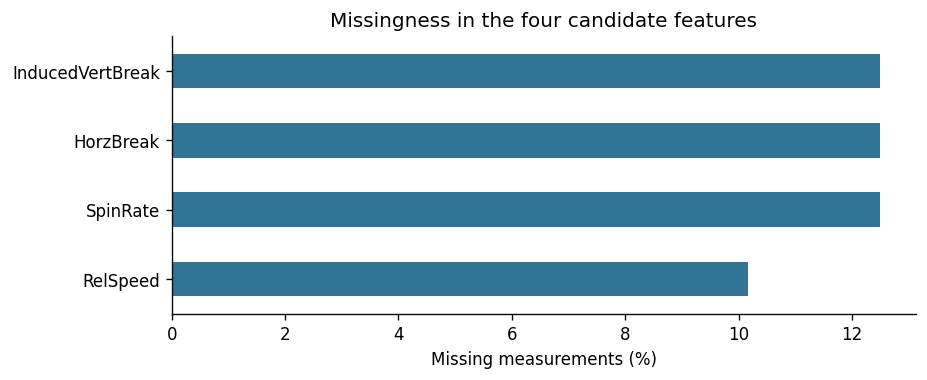

Graph: 01_missingness.png


In [3]:
data = raw.copy()
exact_duplicates = int(data.duplicated().sum())
data = data.drop_duplicates().copy()
data.insert(0, 'source_row', data.index + 2)  # CSV line number including header
for c in data.select_dtypes(include=['object', 'string']).columns:
    data[c] = data[c].astype('string').str.strip().str.replace(r'\s+', ' ', regex=True)
    data[c] = data[c].replace('', pd.NA)
data['TaggedPitchType'] = data['TaggedPitchType'].replace({'RIse': 'Rise'})
conversion_failures = {}
for c in FEATURES:
    before = data[c].notna()
    data[c] = pd.to_numeric(data[c], errors='coerce').replace([np.inf, -np.inf], np.nan)
    conversion_failures[c] = int((before & data[c].isna()).sum())
# Keep the contextual pitch-type field even if this team has no labels.
empty_columns = [c for c in data.columns[data.isna().all()].tolist() if c != 'TaggedPitchType']
data = data.drop(columns=empty_columns)
uuid_duplicates = int(data.loc[data['PitchUUID'].notna(), 'PitchUUID'].duplicated().sum())
assert uuid_duplicates == 0, 'Investigate repeated pitch UUIDs before continuing.'
audit = pd.DataFrame({'missing': data[FEATURES].isna().sum(),
                      'percent_missing': data[FEATURES].isna().mean().mul(100).round(2)})
print('Exact duplicate rows removed:', exact_duplicates)
print('Empty columns excluded:', len(empty_columns), empty_columns)
print('Numeric conversion failures:', conversion_failures)
show_table(audit)
show_table(data[FEATURES].describe().round(3))
print('Pitcher handedness:')
show_table(data.groupby('Pitcher')['PitcherThrows'].first().to_frame())
data.to_csv(RESULTS/'cleaned_all_pitches.csv', index=False)
audit.to_csv(RESULTS/'feature_missingness.csv')
data.groupby('Pitcher')[FEATURES].agg(lambda s: s.isna().sum()).to_csv(RESULTS/'missingness_by_pitcher.csv')
ax = audit['percent_missing'].plot.barh(color='#327496', figsize=(8,3))
ax.set(xlabel='Missing measurements (%)', title='Missingness in the four candidate features')
figure('01_missingness')

## 3. Split and scale
Split 80% training and 20% test within the team, stratifying by pitcher. Then exclude incomplete measurements separately in each set. Learn the scaler on complete training pitches only. The test set represents additional pitches from the same athletes, not unseen pitchers. Correlations and distributions shown here use training data.

Before complete-case exclusion: training = 102 testing = 26
After complete-case exclusion: training = 88 testing = 24
Excluded for missing features: 14 train; 2 test
partition       test  train
Pitcher                    
Kynlee Bowlin      9     37
Maddie Furniss    17     65
                  RelSpeed  SpinRate  HorzBreak  InducedVertBreak
RelSpeed             1.000    -0.544      0.774            -0.768
SpinRate            -0.544     1.000     -0.769             0.887
HorzBreak            0.774    -0.769      1.000            -0.842
InducedVertBreak    -0.768     0.887     -0.842             1.000


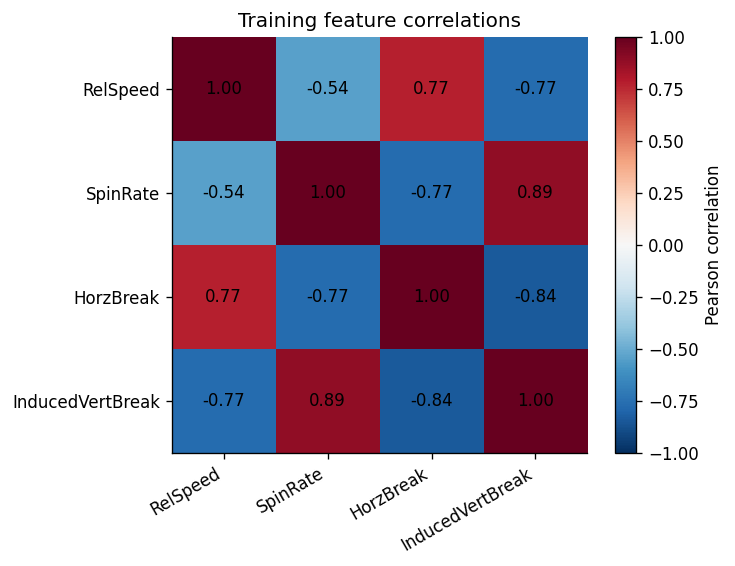

Graph: 02_training_correlations.png


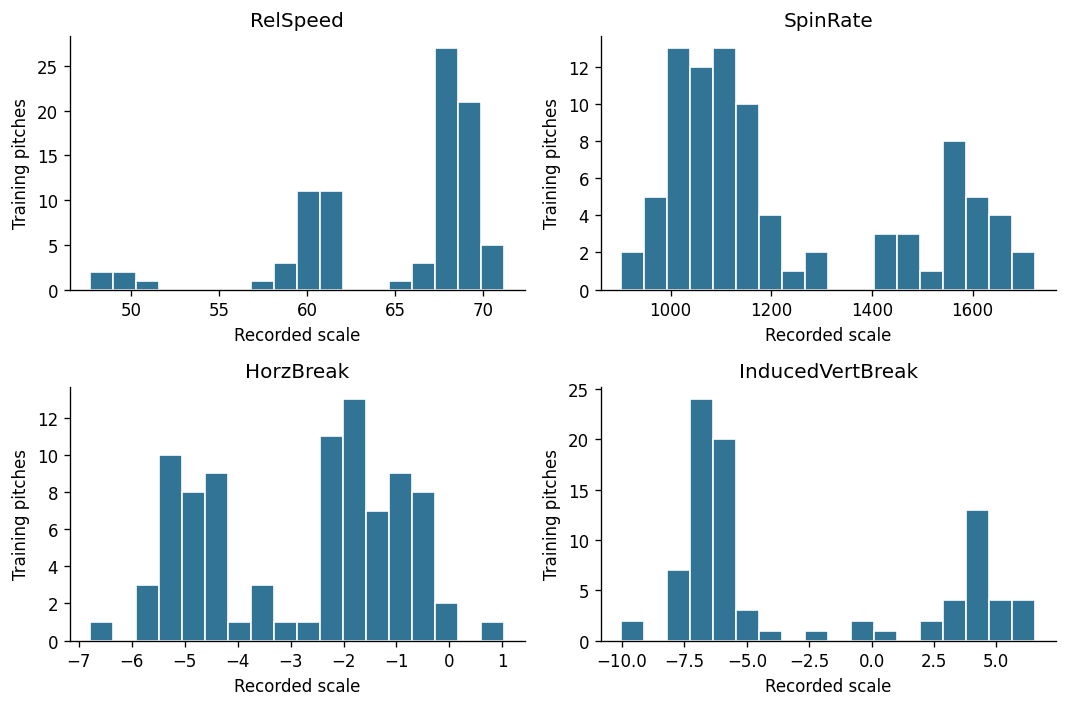

Graph: 03_training_distributions.png


In [4]:
train_raw, test_raw = train_test_split(data, test_size=0.20, random_state=SEED,
                                       stratify=data['Pitcher'])
train = train_raw.dropna(subset=FEATURES).copy()
test = test_raw.dropna(subset=FEATURES).copy()
assert set(train_raw.source_row).isdisjoint(test_raw.source_row)
assert len(train_raw) + len(test_raw) == len(data)
scaler = StandardScaler()
X_train = scaler.fit_transform(train[FEATURES])
X_test = scaler.transform(test[FEATURES])
assert np.isfinite(X_train).all() and np.isfinite(X_test).all()
print('Before complete-case exclusion: training =', len(train_raw), 'testing =', len(test_raw))
print('After complete-case exclusion: training =', len(train), 'testing =', len(test))
print('Excluded for missing features:', len(train_raw)-len(train), 'train;', len(test_raw)-len(test), 'test')
split = data[['source_row','Pitcher']].copy()
split['partition'] = np.where(split.source_row.isin(train_raw.source_row), 'train', 'test')
split['complete_core_features'] = data[FEATURES].notna().all(axis=1)
split.to_csv(RESULTS/'split_manifest.csv', index=False)
show_table(pd.crosstab(split.Pitcher, split.partition))
correlation = train[FEATURES].corr()
show_table(correlation.round(3))
fig, ax = plt.subplots(figsize=(6,4.5))
im=ax.imshow(correlation, vmin=-1, vmax=1, cmap='RdBu_r')
ax.set_xticks(range(4), FEATURES, rotation=30, ha='right'); ax.set_yticks(range(4), FEATURES)
for i in range(4):
    for j in range(4): ax.text(j,i,f'{correlation.iloc[i,j]:.2f}',ha='center',va='center')
fig.colorbar(im, ax=ax, label='Pearson correlation'); ax.set_title('Training feature correlations')
figure('02_training_correlations')
fig, axes = plt.subplots(2,2,figsize=(9,6))
for ax, c in zip(axes.flat, FEATURES):
    ax.hist(train[c], bins=18, color='#327496', edgecolor='white')
    ax.set(title=c, xlabel='Recorded scale', ylabel='Training pitches')
fig.tight_layout(); figure('03_training_distributions')

## 4. Select K-means groups
Use release velocity, spin rate, horizontal movement, and induced vertical movement. These measure speed, rotation, and movement; names, teams, outcomes, and pitch types are excluded from the distance calculations. Standardization prevents spin magnitude from dominating. Compare k=2 through 6 using training silhouette only, with an elbow plot for context. Cluster IDs are arbitrary and do not rank performance. Units were not documented with the export, so values are reported in the recorded scale.

   k  train_silhouette  train_inertia  smallest_train_cluster
0  2            0.7418        70.5156                      31
1  3            0.7686        34.7458                       5
2  4            0.4762        24.9523                       5
3  5            0.4723        21.4782                       5
4  6            0.3497        18.7918                       4
Selected k: 3


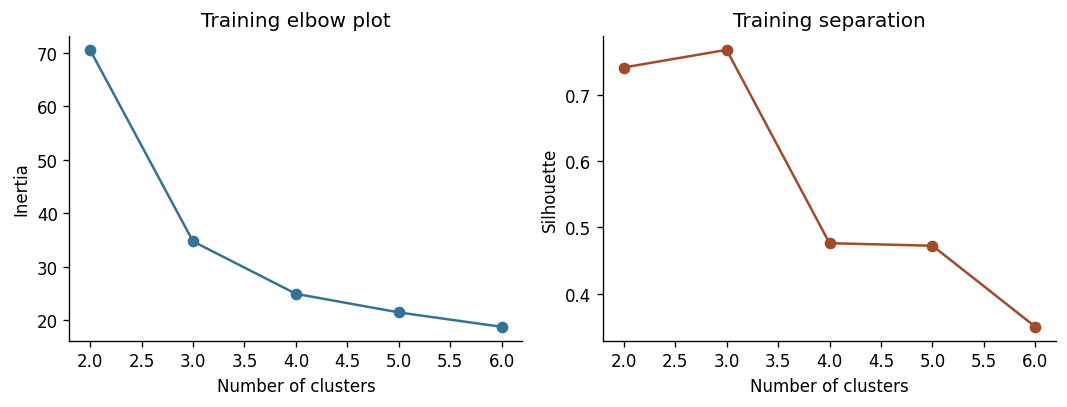

Graph: 04_choose_k.png
         RelSpeed  SpinRate  HorzBreak  InducedVertBreak  training_pitches
cluster                                                                   
0          68.534  1082.186     -1.575            -6.557                57
1          60.580  1570.921     -4.990             4.374                26
2          49.172  1134.871     -4.896             0.394                 5


In [5]:
candidates=[]
models={}
for k in range(2,7):
    model=KMeans(n_clusters=k, n_init=30, random_state=SEED).fit(X_train)
    models[k]=model
    candidates.append({'k':k, 'train_silhouette':sil(X_train, model.labels_),
                       'train_inertia':float(model.inertia_),
                       'smallest_train_cluster':int(np.bincount(model.labels_).min())})
selection=pd.DataFrame(candidates)
best_k=int(selection.loc[selection.train_silhouette.idxmax(),'k'])
km=models[best_k]
train_labels=km.labels_
selection.to_csv(RESULTS/'k_selection_training.csv', index=False)
show_table(selection.round(4)); print('Selected k:',best_k)
fig,axes=plt.subplots(1,2,figsize=(9,3.5))
axes[0].plot(selection.k,selection.train_inertia,'o-',color='#327496')
axes[0].set(xlabel='Number of clusters',ylabel='Inertia',title='Training elbow plot')
axes[1].plot(selection.k,selection.train_silhouette,'o-',color='#a34a28')
axes[1].set(xlabel='Number of clusters',ylabel='Silhouette',title='Training separation')
fig.tight_layout();figure('04_choose_k')
centers=pd.DataFrame(scaler.inverse_transform(km.cluster_centers_),columns=FEATURES)
centers.index.name='cluster'
centers['training_pitches']=np.bincount(train_labels,minlength=best_k)
centers.to_csv(RESULTS/'training_cluster_centers.csv')
show_table(centers.round(3))

## 5. Compare Ward clustering and stability
Ward clustering merges nearby observations to limit growth of within-group variation. Cut its tree at the selected K-means k for a common comparison. ARI quantifies method agreement, not accuracy. Twenty training bootstrap refits assess sensitivity to sampling pitches; they do not establish generalization across athletes or games.

Training Ward silhouette: 0.7686
Training K-means / Ward ARI: 1.0


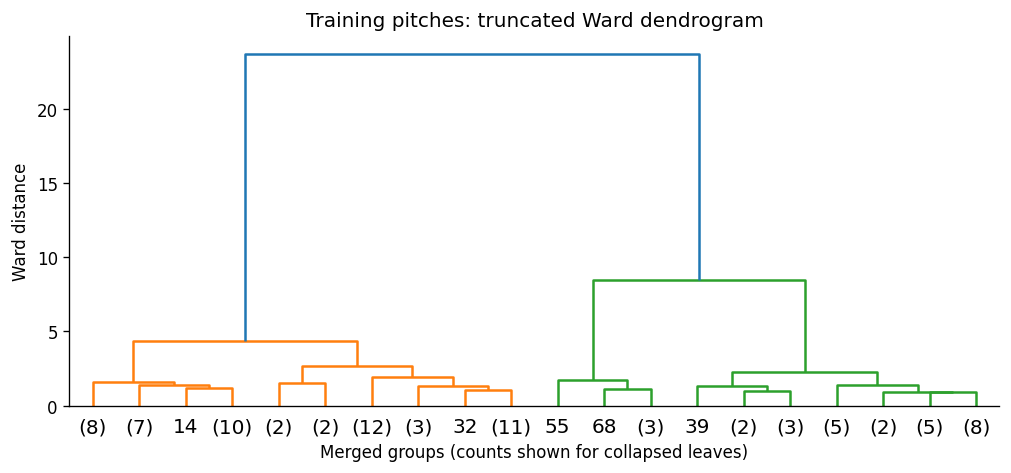

Graph: 05_pitch_dendrogram.png
Bootstrap ARI median/min/max: 1.0 0.7724 1.0


In [6]:
Z=linkage(X_train,method='ward')
hier_labels=cut_tree(Z,n_clusters=best_k).ravel()
method_ari=float(adjusted_rand_score(train_labels,hier_labels))
hier_sil=sil(X_train,hier_labels)
hier_centers=np.vstack([X_train[hier_labels==c].mean(axis=0) for c in range(best_k)])
print('Training Ward silhouette:',round(hier_sil,4))
print('Training K-means / Ward ARI:',round(method_ari,4))
plt.figure(figsize=(10,4));dendrogram(Z,truncate_mode='lastp',p=20,show_leaf_counts=True)
plt.title('Training pitches: truncated Ward dendrogram')
plt.xlabel('Merged groups (counts shown for collapsed leaves)');plt.ylabel('Ward distance')
figure('05_pitch_dendrogram')
rng=np.random.default_rng(SEED)
bootstrap_ari=[]
for b in range(20):
    idx=rng.integers(0,len(X_train),len(X_train))
    refit=KMeans(n_clusters=best_k,n_init=20,random_state=SEED+b).fit(X_train[idx])
    bootstrap_ari.append(adjusted_rand_score(train_labels,refit.predict(X_train)))
print('Bootstrap ARI median/min/max:',*[round(float(v),4) for v in
      [np.median(bootstrap_ari),np.min(bootstrap_ari),np.max(bootstrap_ari)]])
pd.DataFrame({'bootstrap':range(20),'ARI':bootstrap_ari}).to_csv(RESULTS/'training_stability.csv',index=False)

## 6. Fit PCA
PCA is a visualization tool, not a clustering algorithm. Fit it only on this team’s standardized training data, then transform its test data. Clustering still uses all four standardized measurements; the first two PCA components preserve only part of their variation.

In [7]:
pca=PCA().fit(X_train)
PC_train=pca.transform(X_train)
PC_test=pca.transform(X_test)
pca_table=pd.DataFrame({'component':['PC1','PC2','PC3','PC4'],
                        'explained_variance_ratio':pca.explained_variance_ratio_,
                        'cumulative_variance':np.cumsum(pca.explained_variance_ratio_)})
show_table(pca_table.round(4))
coefficients=pd.DataFrame(pca.components_.T,index=FEATURES,columns=pca_table.component)
show_table(coefficients.round(4))
pca_table.to_csv(RESULTS/'pca_variance.csv',index=False)
coefficients.to_csv(RESULTS/'pca_component_coefficients.csv')

  component  explained_variance_ratio  cumulative_variance
0       PC1                    0.8250               0.8250
1       PC2                    0.1176               0.9426
2       PC3                    0.0429               0.9855
3       PC4                    0.0145               1.0000
component            PC1     PC2     PC3     PC4
RelSpeed         -0.4654  0.7423 -0.3331  0.3484
SpinRate          0.4869  0.6434  0.1583 -0.5692
HorzBreak        -0.5139  0.1005  0.8471 -0.0905
InducedVertBreak  0.5313  0.1578  0.3826  0.7392


## 7. Evaluate held-out pitches
Freeze the training model before assigning test pitches. Report silhouette and mean squared standardized distance to learned centers, not classification accuracy. Ward has no native prediction function, so its test comparison explicitly uses nearest training-cluster mean. The composition plot shows whether pitch groups mirror pitcher identity. In a small test sample, some clusters may be absent; undefined silhouettes are reported as NaN.

{
  "selected_k": 3,
  "raw_train_rows": 102,
  "raw_test_rows": 26,
  "complete_train_rows": 88,
  "complete_test_rows": 24,
  "train_silhouette": 0.7685591589010844,
  "test_silhouette": 0.7104878692318447,
  "train_mean_squared_distance": 0.39483812319137973,
  "test_mean_squared_distance": 0.56783175393883,
  "ward_train_silhouette": 0.7685591589010844,
  "train_method_ARI": 1.0,
  "test_method_ARI": 1.0,
  "bootstrap_ARI_median": 1.0,
  "PCA_first_two_variance": 0.942559841204272
}
Test cluster counts: {np.int32(0): np.int64(15), np.int32(1): np.int64(4), np.int32(2): np.int64(5)}


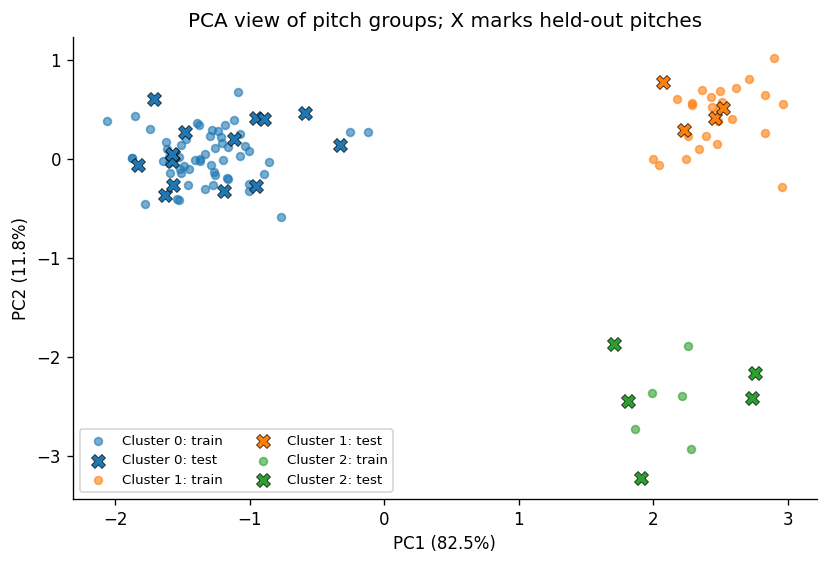

Graph: 06_pitch_pca.png
kmeans_cluster      0     1     2
Pitcher                          
Kynlee Bowlin     0.0  83.9  16.1
Maddie Furniss  100.0   0.0   0.0


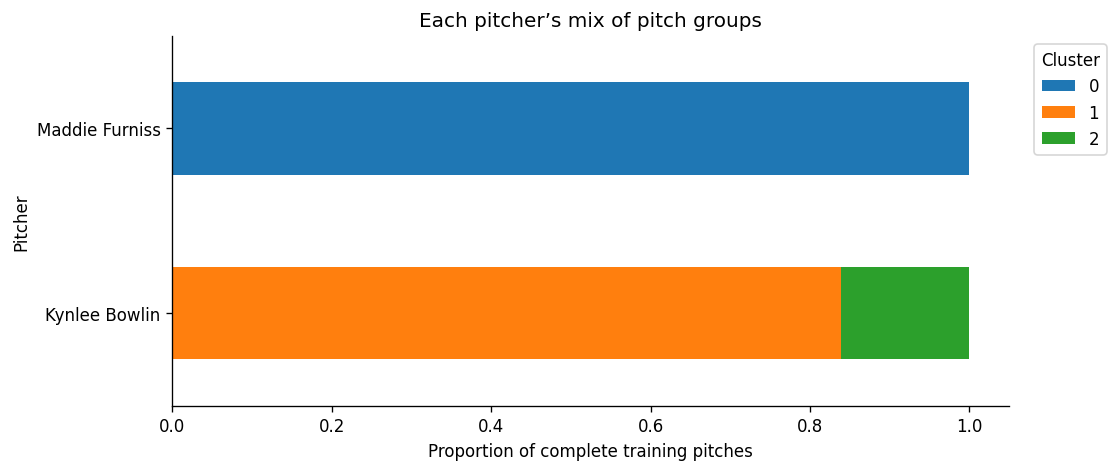

Graph: 07_pitcher_group_mix.png
Training handedness by cluster:
kmeans_cluster   0   1  2
PitcherThrows            
Right           57  26  5
Training pitch labels by cluster (not used to fit):
kmeans_cluster    0   1  2
TaggedPitchType           
Change            0   0  5
Curve            29   1  0
Fast              0   1  0
Rise             19   5  0
Screw             8  19  0
Unlabeled         1   0  0


In [8]:
test_labels=km.predict(X_test)
hier_test=pairwise_distances_argmin(X_test,hier_centers)
train_msd=float(np.mean(np.sum((X_train-km.cluster_centers_[train_labels])**2,axis=1)))
test_msd=float(np.mean(np.sum((X_test-km.cluster_centers_[test_labels])**2,axis=1)))
metrics={'selected_k':best_k,'raw_train_rows':len(train_raw),'raw_test_rows':len(test_raw),
         'complete_train_rows':len(train),'complete_test_rows':len(test),
         'train_silhouette':sil(X_train,train_labels),'test_silhouette':sil(X_test,test_labels),
         'train_mean_squared_distance':train_msd,'test_mean_squared_distance':test_msd,
         'ward_train_silhouette':hier_sil,'train_method_ARI':method_ari,
         'test_method_ARI':float(adjusted_rand_score(test_labels,hier_test)),
         'bootstrap_ARI_median':float(np.median(bootstrap_ari)),
         'PCA_first_two_variance':float(pca.explained_variance_ratio_[:2].sum())}
print(json.dumps(metrics,indent=2))
print('Test cluster counts:',dict(zip(*np.unique(test_labels,return_counts=True))))
train['partition']='train';test['partition']='test'
train['kmeans_cluster']=train_labels;test['kmeans_cluster']=test_labels
train['ward_cluster_or_nearest_mean']=hier_labels
test['ward_cluster_or_nearest_mean']=hier_test
assigned=pd.concat([train,test]).sort_values('source_row')
assigned.to_csv(RESULTS/'complete_case_pitch_assignments.csv',index=False)
fig,ax=plt.subplots(figsize=(8,5))
for c in range(best_k):
    color=plt.get_cmap('tab10')(c)
    ax.scatter(PC_train[train_labels==c,0],PC_train[train_labels==c,1],color=color,s=22,alpha=.6,label=f'Cluster {c}: train')
    ax.scatter(PC_test[test_labels==c,0],PC_test[test_labels==c,1],color=color,marker='X',s=70,edgecolor='black',linewidth=.4,label=f'Cluster {c}: test')
ax.set(xlabel=f'PC1 ({pca.explained_variance_ratio_[0]:.1%})',
       ylabel=f'PC2 ({pca.explained_variance_ratio_[1]:.1%})',title='PCA view of pitch groups; X marks held-out pitches')
ax.legend(fontsize=8,ncol=2);figure('06_pitch_pca')
composition=pd.crosstab(train.Pitcher,train.kmeans_cluster,normalize='index').reindex(columns=range(best_k),fill_value=0)
show_table((composition*100).round(1))
composition.plot.barh(stacked=True,figsize=(9,4),color=[plt.get_cmap('tab10')(c) for c in range(best_k)])
plt.xlabel('Proportion of complete training pitches');plt.title('Each pitcher’s mix of pitch groups')
plt.legend(title='Cluster',bbox_to_anchor=(1.02,1));figure('07_pitcher_group_mix')
composition.to_csv(RESULTS/'training_pitcher_cluster_proportions.csv')
print('Training handedness by cluster:');show_table(pd.crosstab(train.PitcherThrows,train.kmeans_cluster))
print('Training pitch labels by cluster (not used to fit):')
show_table(pd.crosstab(train.TaggedPitchType.fillna('Unlabeled'),train.kmeans_cluster))

## 8. Compare pitcher profiles
Aggregate complete training pitches into a mean profile for each pitcher and report counts. Averages depend on the observed pitch mix. For UTA, two athletes permit a descriptive comparison only: a two-group clustering would simply put each athlete in a singleton group. South Dakota State’s four profiles allow an illustrative two-group view, but neither team has enough athletes for a general style taxonomy. The profile dendrogram only visualizes these few observed means.

                RelSpeed  SpinRate  HorzBreak  InducedVertBreak  training_pitches throwing_hand
Pitcher                                                                                        
Kynlee Bowlin     58.740  1500.590     -4.975             3.732                31         Right
Maddie Furniss    68.534  1082.186     -1.575            -6.557                57         Right
Two pitcher profiles: descriptive comparison only; no pitcher-style clusters or silhouette are fitted.


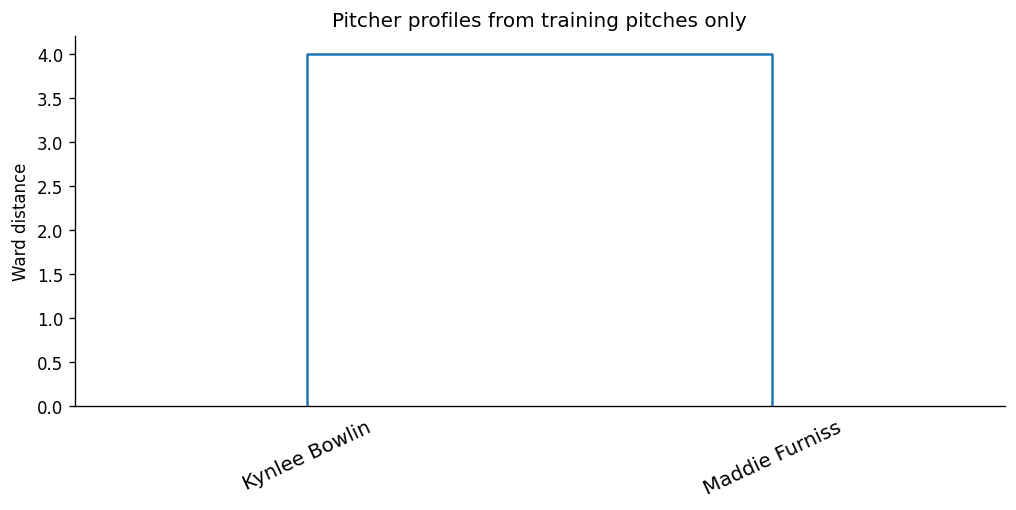

Graph: 08_pitcher_dendrogram.png


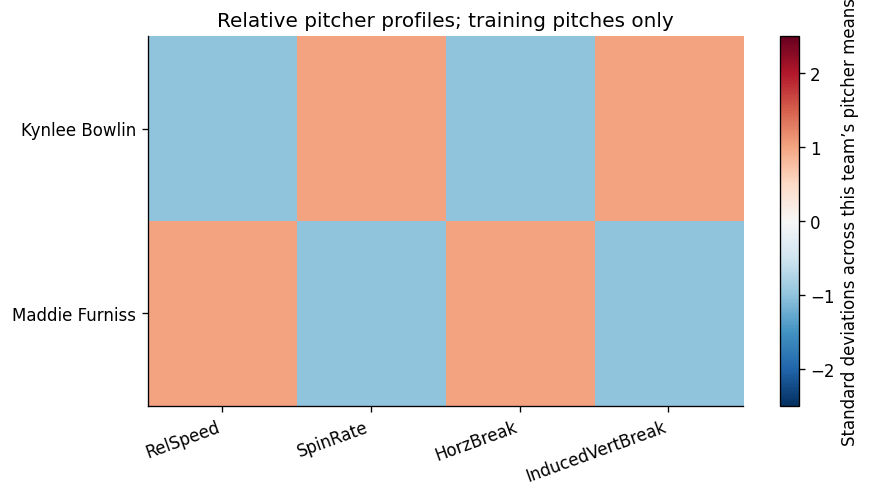

Graph: 09_pitcher_profiles.png
Held-out mean minus training mean, recorded scale:
                RelSpeed  SpinRate  HorzBreak  InducedVertBreak
Pitcher                                                        
Kynlee Bowlin     -4.488  -148.975      0.168            -2.034
Maddie Furniss    -0.030    20.270      0.030             0.173


In [9]:
profiles=train.groupby('Pitcher')[FEATURES].mean()
profile_counts=train.groupby('Pitcher').size().rename('training_pitches')
heldout_profiles=test.groupby('Pitcher')[FEATURES].mean().reindex(profiles.index)
profile_scaler=StandardScaler()
Xp=profile_scaler.fit_transform(profiles)
profile_km = KMeans(n_clusters=2,n_init=30,random_state=SEED).fit(Xp) if len(profiles)>2 else None
profile_results=profiles.join(profile_counts)
if profile_km is not None:
    profile_results['illustrative_style_group']=profile_km.labels_
profile_results['throwing_hand']=train.groupby('Pitcher').PitcherThrows.first()
show_table(profile_results.round(3))
profile_results.to_csv(RESULTS/'training_pitcher_profiles.csv')
heldout_profiles.to_csv(RESULTS/'heldout_pitcher_profiles.csv')
if profile_km is not None:
    print('Illustrative pitcher-profile silhouette:',round(sil(Xp,profile_km.labels_),4))
else:
    print('Two pitcher profiles: descriptive comparison only; no pitcher-style clusters or silhouette are fitted.')
plt.figure(figsize=(10,4));dendrogram(linkage(Xp,method='ward'),labels=profiles.index.tolist(),leaf_rotation=25)
plt.ylabel('Ward distance');plt.title('Pitcher profiles from training pitches only')
figure('08_pitcher_dendrogram')
fig,ax=plt.subplots(figsize=(8,4))
im=ax.imshow(Xp,cmap='RdBu_r',vmin=-2.5,vmax=2.5,aspect='auto')
ax.set_xticks(range(4),FEATURES,rotation=20,ha='right');ax.set_yticks(range(len(profiles)),profiles.index)
fig.colorbar(im,ax=ax,label='Standard deviations across this team’s pitcher means')
ax.set_title('Relative pitcher profiles; training pitches only');figure('09_pitcher_profiles')
profile_differences=(heldout_profiles-profiles)
print('Held-out mean minus training mean, recorded scale:')
show_table(profile_differences.round(3))
profile_differences.to_csv(RESULTS/'heldout_minus_train_pitcher_means.csv')

## 9. Check preprocessing sensitivity
Repeat training comparisons using robust scaling, absolute horizontal movement, omitting spin, and median imputation. Keep k fixed and compare assignments on the same complete training pitches. Missing all four features is not imputed into an artificial average pitch. Absolute horizontal movement tests sensitivity to direction and handedness, at the cost of discarding direction. Silhouettes from different feature spaces should not be used to rank the alternatives directly.

In [10]:
sensitivity=[]
for name,cols,transform in [
    ('Robust scaling',FEATURES,RobustScaler()),
    ('Absolute horizontal movement',FEATURES,StandardScaler()),
    ('Velocity plus movement',['RelSpeed','HorzBreak','InducedVertBreak'],StandardScaler())]:
    frame=train[cols].copy()
    if name=='Absolute horizontal movement': frame['HorzBreak']=frame.HorzBreak.abs()
    xx=transform.fit_transform(frame)
    alternative=KMeans(n_clusters=best_k,n_init=30,random_state=SEED).fit(xx)
    sensitivity.append({'choice':name,'train_rows':len(frame),'silhouette_in_own_space':sil(xx,alternative.labels_),
                        'ARI_vs_baseline':float(adjusted_rand_score(train_labels,alternative.labels_))})
impute_rows=train_raw.dropna(subset=FEATURES,how='all')
imputer=SimpleImputer(strategy='median')
imputed=imputer.fit_transform(impute_rows[FEATURES])
impute_scaler=StandardScaler().fit(imputed)
impute_x=impute_scaler.transform(imputed)
impute_model=KMeans(n_clusters=best_k,n_init=30,random_state=SEED).fit(impute_x)
common_x=impute_scaler.transform(imputer.transform(train[FEATURES]))
sensitivity.append({'choice':'Training median imputation','train_rows':len(impute_rows),
                    'silhouette_in_own_space':sil(impute_x,impute_model.labels_),
                    'ARI_vs_baseline':float(adjusted_rand_score(train_labels,impute_model.predict(common_x)))})
sensitivity=pd.DataFrame(sensitivity)
show_table(sensitivity.round(4));sensitivity.to_csv(RESULTS/'training_sensitivity.csv',index=False)

                         choice  train_rows  silhouette_in_own_space  ARI_vs_baseline
0                Robust scaling          88                   0.7793              1.0
1  Absolute horizontal movement          88                   0.7720              1.0
2        Velocity plus movement          88                   0.7716              1.0
3    Training median imputation          90                   0.7561              1.0


## 10. Summarize this team
The output records all metrics and package versions. Check which pitchers contribute to each group before naming a style. All conclusions are limited to this game, and no cluster indicates superior performance. The original CSV stays unchanged.

In [11]:
summary = f"""Question 5: Can we identify different pitching styles based on velocity, spin rate, and ball movement?

The file has {len(raw)} pitches, {raw.shape[1]} columns and {data.Pitcher.nunique()} pitchers.
The 80/20 pitch split produced {len(train_raw)} training and {len(test_raw)} test rows before missing-feature exclusions.
The complete-case analysis used {len(train)} training pitches and {len(test)} test pitches.
Training silhouette selected k={best_k} among k=2..6.
K-means silhouette: training {metrics['train_silhouette']:.3f}; test {metrics['test_silhouette']:.3f}.
Mean squared standardized distance to training centers: train {train_msd:.3f}; test {test_msd:.3f}.
Ward versus K-means training ARI: {method_ari:.3f}.
Bootstrap median ARI: {metrics['bootstrap_ARI_median']:.3f}.
The first two PCA components preserve {metrics['PCA_first_two_variance']:.1%} of training variation.

These results describe pitch groups and exploratory pitcher profiles within one game.
They do not establish stable population-level pitching styles or identify superior pitchers.
Signed movement, pitcher identity, missing tracking, unequal pitch counts and repertoire mix limit interpretation.
"""
print(summary)
(RESULTS/'summary.txt').write_text(summary,encoding='utf-8')
(RESULTS/'metrics.json').write_text(json.dumps(metrics,indent=2),encoding='utf-8')
versions={'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,
          'scipy':scipy.__version__,'scikit-learn':sklearn.__version__,'matplotlib':matplotlib.__version__}
print('Versions:',versions)
(RESULTS/'versions.json').write_text(json.dumps(versions,indent=2),encoding='utf-8')
assert sum(np.bincount(train_labels))==len(train)
assert sum(np.bincount(test_labels,minlength=best_k))==len(test)
assert len(assigned)==len(train)+len(test)
assert np.allclose(scaler.mean_,train[FEATURES].mean().values)
assert assigned.source_row.is_unique
print('Verification passed: partitions disjoint, counts reconcile, finite features, training-only scale parameters.')

Question 5: Can we identify different pitching styles based on velocity, spin rate, and ball movement?

The file has 128 pitches, 125 columns and 2 pitchers.
The 80/20 pitch split produced 102 training and 26 test rows before missing-feature exclusions.
The complete-case analysis used 88 training pitches and 24 test pitches.
Training silhouette selected k=3 among k=2..6.
K-means silhouette: training 0.769; test 0.710.
Mean squared standardized distance to training centers: train 0.395; test 0.568.
Ward versus K-means training ARI: 1.000.
Bootstrap median ARI: 1.000.
The first two PCA components preserve 94.3% of training variation.

These results describe pitch groups and exploratory pitcher profiles within one game.
They do not establish stable population-level pitching styles or identify superior pitchers.
Signed movement, pitcher identity, missing tracking, unequal pitch counts and repertoire mix limit interpretation.

Versions: {'python': '3.13.16', 'numpy': '2.1.3', 'pandas': '2.2

## Observed UTA findings
The team has 128 recorded pitches and 2 pitchers. Before exclusions, the split contains 102 training and 26 test rows. Complete-case clustering uses 88 training and 24 test pitches. Training silhouette selects 3 groups. Training silhouette is 0.769; test silhouette is 0.710. The first two PCA components retain 94.3% of training variation.

Training group composition by pitcher:
Kynlee Bowlin: cluster 0 = 0.0%, cluster 1 = 83.9%, cluster 2 = 16.1%

Maddie Furniss: cluster 0 = 100.0%, cluster 1 = 0.0%, cluster 2 = 0.0%

These are within-team patterns, not evidence of team superiority or population-level styles.

## Interpreting UTA’s groups
The selected three-group pitch model places all 57 complete training pitches from Maddie Furniss in cluster 0. Kynlee Bowlin contributes 26 pitches to cluster 1 and five to cluster 2. In the recorded scale, the centers have mean velocity/spin of 68.53/1082.19, 60.58/1570.92, and 49.17/1134.87 respectively. The five-pitch group is substantially slower than Bowlin’s other group. This is consistent with variation in her observed pitch mix; physical measurements alone do not verify a named pitch type. There are three groups of pitches but only two pitchers, so the three groups must not be presented as three pitcher styles. The small group needs more observations before drawing a stable conclusion.


# South Dakota State
Independent analysis for this team.

## 1. Load this team only
Filter by PitcherTeam before cleaning and splitting. Preserve original row indices so source_row still points to the CSV line. The full source file contains both teams; this analysis uses only the selected team.

In [12]:
from pathlib import Path
import json, platform
import numpy as np
import pandas as pd
import scipy
import sklearn
import matplotlib
get_ipython().run_line_magic('matplotlib','inline')
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import silhouette_score, adjusted_rand_score, pairwise_distances_argmin
from threadpoolctl import threadpool_limits
threadpool_limits(limits=1)

BASE = Path.cwd()
SOURCE = CSV_PATH
RESULTS = BASE / 'team_results' / 'South_Dakota_State'
RESULTS.mkdir(parents=True, exist_ok=True)
FEATURES = ['RelSpeed', 'SpinRate', 'HorzBreak', 'InducedVertBreak']
SEED = 42
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'savefig.bbox': 'tight'})
def figure(name):
    path = RESULTS / (name + '.png')
    plt.savefig(path, dpi=150)
    plt.show()
    plt.close()
    print('Graph:', path.name)
def show_table(frame):
    print(frame.to_string())
def sil(x, labels):
    return float(silhouette_score(x, labels)) if 1 < len(np.unique(labels)) < len(labels) else float('nan')
full_data = pd.read_csv(SOURCE)
raw = full_data.loc[full_data['PitcherTeam'].astype('string').str.strip().str.lower().str.startswith('south dakota', na=False)].copy()
assert len(raw)>0, 'Team filter returned no rows.'
print('Team: South_Dakota_State')
print('Raw shape:', raw.shape)
print('Dates:', raw['Date'].value_counts(dropna=False).to_dict())
print('Teams:', raw['PitcherTeam'].value_counts(dropna=False).to_dict())
print('Pitchers:', raw['Pitcher'].nunique())

Team: South_Dakota_State
Raw shape: (131, 125)
Dates: {'3/14/2026': 131}
Teams: {'South dakota state [sou03:2025]': 131}
Pitchers: 4


## 2. Clean and audit
Standardize whitespace and the RIse label, verify numeric core measurements, check duplicate IDs and exact duplicate rows, and report empty fields. Missing measurements are not zero. No arbitrary outlier deletion is performed.

Exact duplicate rows removed: 0
Empty columns excluded: 13 ['BatterId', 'PitcherSet', 'AutoPitchType', 'Notes', 'LastTrackedDistance', 'Stadium', 'Level', 'League', 'yt_FSRI', 'yt_SessionName', 'Note', 'yt_SeamLat', 'yt_SeamLong']
Numeric conversion failures: {'RelSpeed': 0, 'SpinRate': 0, 'HorzBreak': 0, 'InducedVertBreak': 0}
                  missing  percent_missing
RelSpeed                7             5.34
SpinRate                7             5.34
HorzBreak               7             5.34
InducedVertBreak        7             5.34
       RelSpeed  SpinRate  HorzBreak  InducedVertBreak
count   124.000   124.000    124.000           124.000
mean     64.328  1123.748      0.281            -3.070
std       3.504   174.019      2.771             2.525
min      51.885   649.594     -4.643            -8.893
25%      62.681   982.672     -1.969            -4.700
50%      64.799  1136.774      0.370            -2.671
75%      66.927  1226.809      2.722            -1.449
max      70.321

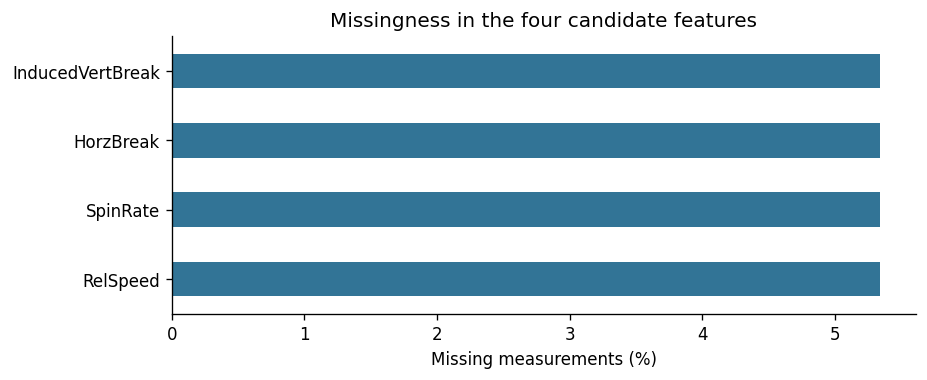

Graph: 01_missingness.png


In [13]:
data = raw.copy()
exact_duplicates = int(data.duplicated().sum())
data = data.drop_duplicates().copy()
data.insert(0, 'source_row', data.index + 2)  # CSV line number including header
for c in data.select_dtypes(include=['object', 'string']).columns:
    data[c] = data[c].astype('string').str.strip().str.replace(r'\s+', ' ', regex=True)
    data[c] = data[c].replace('', pd.NA)
data['TaggedPitchType'] = data['TaggedPitchType'].replace({'RIse': 'Rise'})
conversion_failures = {}
for c in FEATURES:
    before = data[c].notna()
    data[c] = pd.to_numeric(data[c], errors='coerce').replace([np.inf, -np.inf], np.nan)
    conversion_failures[c] = int((before & data[c].isna()).sum())
# Keep the contextual pitch-type field even if this team has no labels.
empty_columns = [c for c in data.columns[data.isna().all()].tolist() if c != 'TaggedPitchType']
data = data.drop(columns=empty_columns)
uuid_duplicates = int(data.loc[data['PitchUUID'].notna(), 'PitchUUID'].duplicated().sum())
assert uuid_duplicates == 0, 'Investigate repeated pitch UUIDs before continuing.'
audit = pd.DataFrame({'missing': data[FEATURES].isna().sum(),
                      'percent_missing': data[FEATURES].isna().mean().mul(100).round(2)})
print('Exact duplicate rows removed:', exact_duplicates)
print('Empty columns excluded:', len(empty_columns), empty_columns)
print('Numeric conversion failures:', conversion_failures)
show_table(audit)
show_table(data[FEATURES].describe().round(3))
print('Pitcher handedness:')
show_table(data.groupby('Pitcher')['PitcherThrows'].first().to_frame())
data.to_csv(RESULTS/'cleaned_all_pitches.csv', index=False)
audit.to_csv(RESULTS/'feature_missingness.csv')
data.groupby('Pitcher')[FEATURES].agg(lambda s: s.isna().sum()).to_csv(RESULTS/'missingness_by_pitcher.csv')
ax = audit['percent_missing'].plot.barh(color='#327496', figsize=(8,3))
ax.set(xlabel='Missing measurements (%)', title='Missingness in the four candidate features')
figure('01_missingness')

## 3. Split and scale
Split 80% training and 20% test within the team, stratifying by pitcher. Then exclude incomplete measurements separately in each set. Learn the scaler on complete training pitches only. The test set represents additional pitches from the same athletes, not unseen pitchers. Correlations and distributions shown here use training data.

Before complete-case exclusion: training = 104 testing = 27
After complete-case exclusion: training = 100 testing = 24
Excluded for missing features: 4 train; 3 test
partition       test  train
Pitcher                    
Bella Macmahon     2      6
Grace Proctor     11     43
Keira Carrillo     4     14
Tayler Baker      10     41
                  RelSpeed  SpinRate  HorzBreak  InducedVertBreak
RelSpeed             1.000     0.443     -0.236             0.299
SpinRate             0.443     1.000     -0.074             0.140
HorzBreak           -0.236    -0.074      1.000            -0.049
InducedVertBreak     0.299     0.140     -0.049             1.000


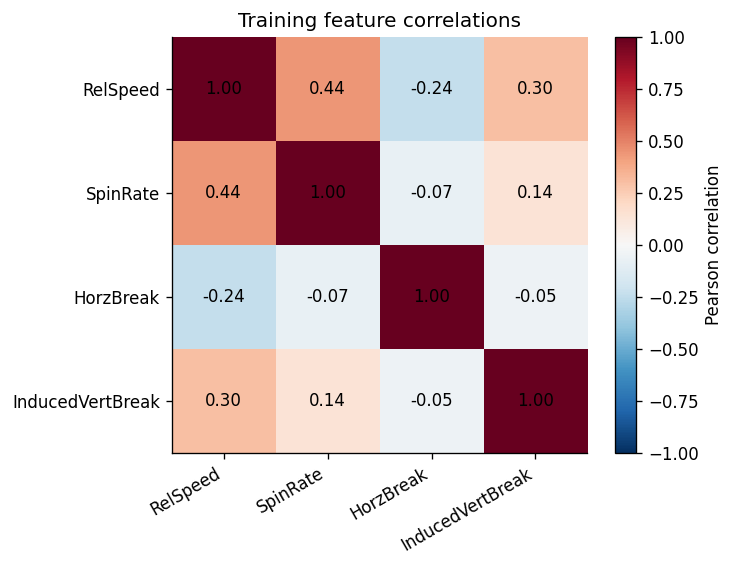

Graph: 02_training_correlations.png


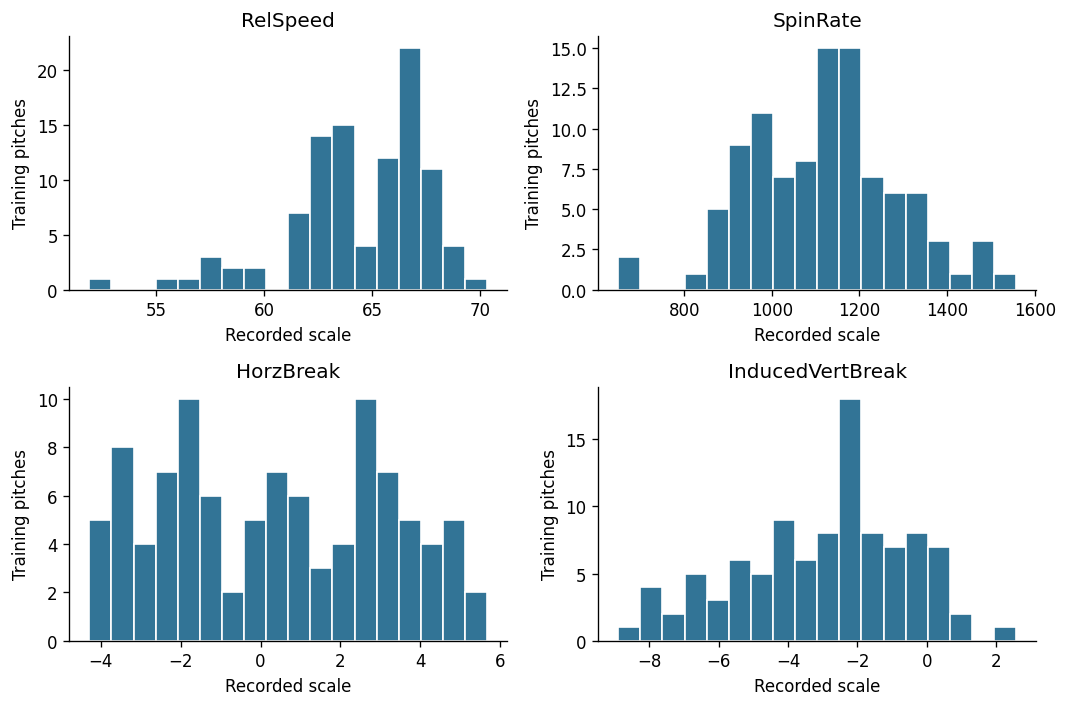

Graph: 03_training_distributions.png


In [14]:
train_raw, test_raw = train_test_split(data, test_size=0.20, random_state=SEED,
                                       stratify=data['Pitcher'])
train = train_raw.dropna(subset=FEATURES).copy()
test = test_raw.dropna(subset=FEATURES).copy()
assert set(train_raw.source_row).isdisjoint(test_raw.source_row)
assert len(train_raw) + len(test_raw) == len(data)
scaler = StandardScaler()
X_train = scaler.fit_transform(train[FEATURES])
X_test = scaler.transform(test[FEATURES])
assert np.isfinite(X_train).all() and np.isfinite(X_test).all()
print('Before complete-case exclusion: training =', len(train_raw), 'testing =', len(test_raw))
print('After complete-case exclusion: training =', len(train), 'testing =', len(test))
print('Excluded for missing features:', len(train_raw)-len(train), 'train;', len(test_raw)-len(test), 'test')
split = data[['source_row','Pitcher']].copy()
split['partition'] = np.where(split.source_row.isin(train_raw.source_row), 'train', 'test')
split['complete_core_features'] = data[FEATURES].notna().all(axis=1)
split.to_csv(RESULTS/'split_manifest.csv', index=False)
show_table(pd.crosstab(split.Pitcher, split.partition))
correlation = train[FEATURES].corr()
show_table(correlation.round(3))
fig, ax = plt.subplots(figsize=(6,4.5))
im=ax.imshow(correlation, vmin=-1, vmax=1, cmap='RdBu_r')
ax.set_xticks(range(4), FEATURES, rotation=30, ha='right'); ax.set_yticks(range(4), FEATURES)
for i in range(4):
    for j in range(4): ax.text(j,i,f'{correlation.iloc[i,j]:.2f}',ha='center',va='center')
fig.colorbar(im, ax=ax, label='Pearson correlation'); ax.set_title('Training feature correlations')
figure('02_training_correlations')
fig, axes = plt.subplots(2,2,figsize=(9,6))
for ax, c in zip(axes.flat, FEATURES):
    ax.hist(train[c], bins=18, color='#327496', edgecolor='white')
    ax.set(title=c, xlabel='Recorded scale', ylabel='Training pitches')
fig.tight_layout(); figure('03_training_distributions')

## 4. Select K-means groups
Use release velocity, spin rate, horizontal movement, and induced vertical movement. These measure speed, rotation, and movement; names, teams, outcomes, and pitch types are excluded from the distance calculations. Standardization prevents spin magnitude from dominating. Compare k=2 through 6 using training silhouette only, with an elbow plot for context. Cluster IDs are arbitrary and do not rank performance. Units were not documented with the export, so values are reported in the recorded scale.

   k  train_silhouette  train_inertia  smallest_train_cluster
0  2            0.3230       273.2229                      46
1  3            0.3543       201.4581                      10
2  4            0.3875       147.8534                      10
3  5            0.4339       102.2044                      10
4  6            0.4437        90.0021                       4
Selected k: 6


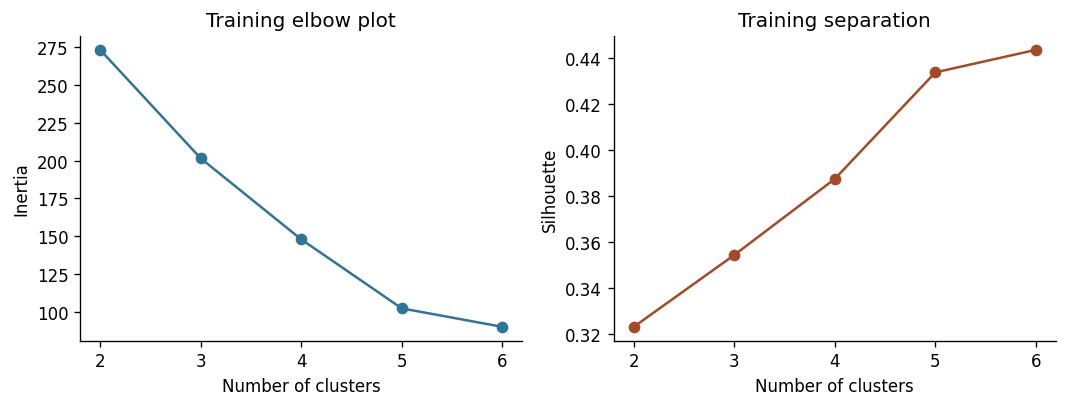

Graph: 04_choose_k.png
         RelSpeed  SpinRate  HorzBreak  InducedVertBreak  training_pitches
cluster                                                                   
0          64.196  1076.119      1.751            -5.770                22
1          67.140  1321.433     -2.468            -2.429                25
2          66.738   990.136     -0.530            -0.871                21
3          57.981   959.648      1.778            -7.012                 4
4          62.668  1167.344      3.969            -1.588                22
5          56.656   810.836     -3.288            -4.847                 6


In [15]:
candidates=[]
models={}
for k in range(2,7):
    model=KMeans(n_clusters=k, n_init=30, random_state=SEED).fit(X_train)
    models[k]=model
    candidates.append({'k':k, 'train_silhouette':sil(X_train, model.labels_),
                       'train_inertia':float(model.inertia_),
                       'smallest_train_cluster':int(np.bincount(model.labels_).min())})
selection=pd.DataFrame(candidates)
best_k=int(selection.loc[selection.train_silhouette.idxmax(),'k'])
km=models[best_k]
train_labels=km.labels_
selection.to_csv(RESULTS/'k_selection_training.csv', index=False)
show_table(selection.round(4)); print('Selected k:',best_k)
fig,axes=plt.subplots(1,2,figsize=(9,3.5))
axes[0].plot(selection.k,selection.train_inertia,'o-',color='#327496')
axes[0].set(xlabel='Number of clusters',ylabel='Inertia',title='Training elbow plot')
axes[1].plot(selection.k,selection.train_silhouette,'o-',color='#a34a28')
axes[1].set(xlabel='Number of clusters',ylabel='Silhouette',title='Training separation')
fig.tight_layout();figure('04_choose_k')
centers=pd.DataFrame(scaler.inverse_transform(km.cluster_centers_),columns=FEATURES)
centers.index.name='cluster'
centers['training_pitches']=np.bincount(train_labels,minlength=best_k)
centers.to_csv(RESULTS/'training_cluster_centers.csv')
show_table(centers.round(3))

## 5. Compare Ward clustering and stability
Ward clustering merges nearby observations to limit growth of within-group variation. Cut its tree at the selected K-means k for a common comparison. ARI quantifies method agreement, not accuracy. Twenty training bootstrap refits assess sensitivity to sampling pitches; they do not establish generalization across athletes or games.

Training Ward silhouette: 0.414
Training K-means / Ward ARI: 0.8752


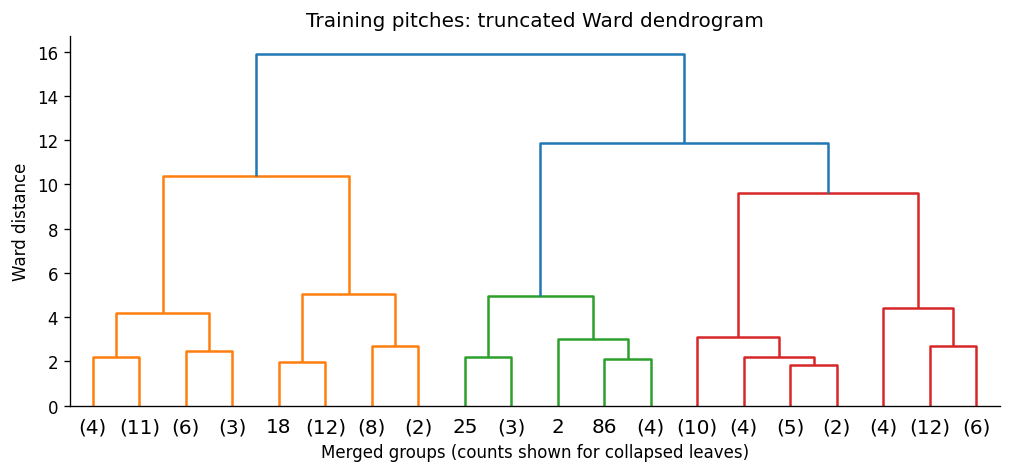

Graph: 05_pitch_dendrogram.png
Bootstrap ARI median/min/max: 0.8689 0.7861 1.0


In [16]:
Z=linkage(X_train,method='ward')
hier_labels=cut_tree(Z,n_clusters=best_k).ravel()
method_ari=float(adjusted_rand_score(train_labels,hier_labels))
hier_sil=sil(X_train,hier_labels)
hier_centers=np.vstack([X_train[hier_labels==c].mean(axis=0) for c in range(best_k)])
print('Training Ward silhouette:',round(hier_sil,4))
print('Training K-means / Ward ARI:',round(method_ari,4))
plt.figure(figsize=(10,4));dendrogram(Z,truncate_mode='lastp',p=20,show_leaf_counts=True)
plt.title('Training pitches: truncated Ward dendrogram')
plt.xlabel('Merged groups (counts shown for collapsed leaves)');plt.ylabel('Ward distance')
figure('05_pitch_dendrogram')
rng=np.random.default_rng(SEED)
bootstrap_ari=[]
for b in range(20):
    idx=rng.integers(0,len(X_train),len(X_train))
    refit=KMeans(n_clusters=best_k,n_init=20,random_state=SEED+b).fit(X_train[idx])
    bootstrap_ari.append(adjusted_rand_score(train_labels,refit.predict(X_train)))
print('Bootstrap ARI median/min/max:',*[round(float(v),4) for v in
      [np.median(bootstrap_ari),np.min(bootstrap_ari),np.max(bootstrap_ari)]])
pd.DataFrame({'bootstrap':range(20),'ARI':bootstrap_ari}).to_csv(RESULTS/'training_stability.csv',index=False)

## 6. Fit PCA
PCA is a visualization tool, not a clustering algorithm. Fit it only on this team’s standardized training data, then transform its test data. Clustering still uses all four standardized measurements; the first two PCA components preserve only part of their variation.

In [17]:
pca=PCA().fit(X_train)
PC_train=pca.transform(X_train)
PC_test=pca.transform(X_test)
pca_table=pd.DataFrame({'component':['PC1','PC2','PC3','PC4'],
                        'explained_variance_ratio':pca.explained_variance_ratio_,
                        'cumulative_variance':np.cumsum(pca.explained_variance_ratio_)})
show_table(pca_table.round(4))
coefficients=pd.DataFrame(pca.components_.T,index=FEATURES,columns=pca_table.component)
show_table(coefficients.round(4))
pca_table.to_csv(RESULTS/'pca_variance.csv',index=False)
coefficients.to_csv(RESULTS/'pca_component_coefficients.csv')

  component  explained_variance_ratio  cumulative_variance
0       PC1                    0.4199               0.4199
1       PC2                    0.2402               0.6602
2       PC3                    0.2165               0.8766
3       PC4                    0.1234               1.0000
component            PC1     PC2     PC3     PC4
RelSpeed          0.6513  0.0004 -0.0948  0.7529
SpinRate          0.5460  0.1921 -0.6036 -0.5484
HorzBreak        -0.3163  0.8883 -0.2259  0.2448
InducedVertBreak  0.4215  0.4173  0.7587 -0.2693


## 7. Evaluate held-out pitches
Freeze the training model before assigning test pitches. Report silhouette and mean squared standardized distance to learned centers, not classification accuracy. Ward has no native prediction function, so its test comparison explicitly uses nearest training-cluster mean. The composition plot shows whether pitch groups mirror pitcher identity. In a small test sample, some clusters may be absent; undefined silhouettes are reported as NaN.

{
  "selected_k": 6,
  "raw_train_rows": 104,
  "raw_test_rows": 27,
  "complete_train_rows": 100,
  "complete_test_rows": 24,
  "train_silhouette": 0.4437105884512491,
  "test_silhouette": 0.36538910374251454,
  "train_mean_squared_distance": 0.9000207384230611,
  "test_mean_squared_distance": 1.2040127150154847,
  "ward_train_silhouette": 0.41395092064697836,
  "train_method_ARI": 0.8752402669500126,
  "test_method_ARI": 0.8072433403172703,
  "bootstrap_ARI_median": 0.8688901524456711,
  "PCA_first_two_variance": 0.6601708455861282
}
Test cluster counts: {np.int32(0): np.int64(6), np.int32(1): np.int64(6), np.int32(2): np.int64(4), np.int32(3): np.int64(1), np.int32(4): np.int64(4), np.int32(5): np.int64(3)}


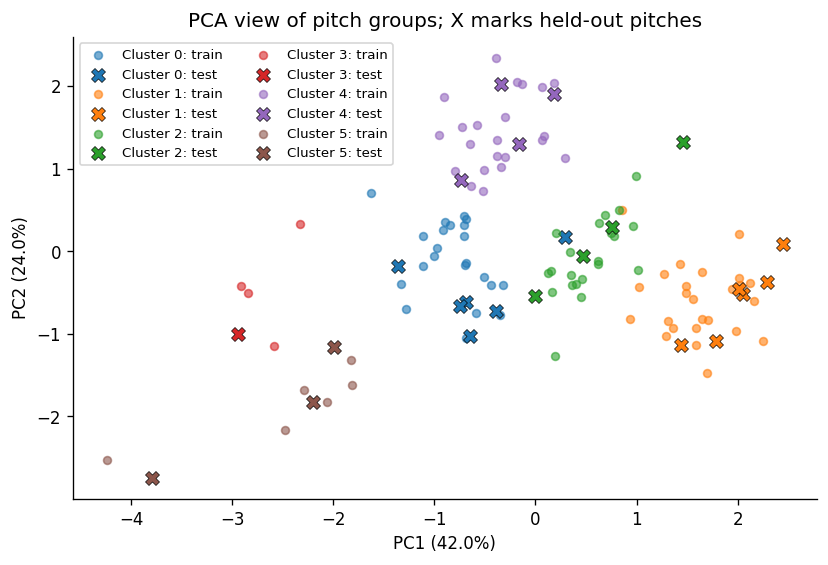

Graph: 06_pitch_pca.png
kmeans_cluster     0     1     2    3     4     5
Pitcher                                          
Bella Macmahon  66.7   0.0   0.0  0.0   0.0  33.3
Grace Proctor   42.9   0.0   0.0  7.1  50.0   0.0
Keira Carrillo   0.0   7.7  76.9  7.7   7.7   0.0
Tayler Baker     0.0  61.5  28.2  0.0   0.0  10.3


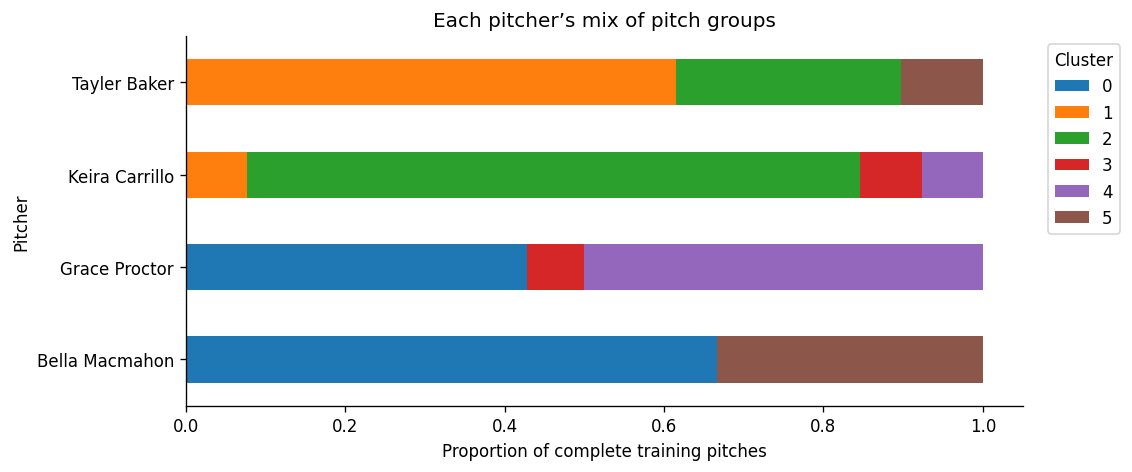

Graph: 07_pitcher_group_mix.png
Training handedness by cluster:
kmeans_cluster   0   1   2  3   4  5
PitcherThrows                       
Left            18   0   0  3  21  0
Right            4  25  21  1   1  6
Training pitch labels by cluster (not used to fit):
kmeans_cluster    0   1   2  3   4  5
TaggedPitchType                      
Unlabeled        22  25  21  4  22  6


In [18]:
test_labels=km.predict(X_test)
hier_test=pairwise_distances_argmin(X_test,hier_centers)
train_msd=float(np.mean(np.sum((X_train-km.cluster_centers_[train_labels])**2,axis=1)))
test_msd=float(np.mean(np.sum((X_test-km.cluster_centers_[test_labels])**2,axis=1)))
metrics={'selected_k':best_k,'raw_train_rows':len(train_raw),'raw_test_rows':len(test_raw),
         'complete_train_rows':len(train),'complete_test_rows':len(test),
         'train_silhouette':sil(X_train,train_labels),'test_silhouette':sil(X_test,test_labels),
         'train_mean_squared_distance':train_msd,'test_mean_squared_distance':test_msd,
         'ward_train_silhouette':hier_sil,'train_method_ARI':method_ari,
         'test_method_ARI':float(adjusted_rand_score(test_labels,hier_test)),
         'bootstrap_ARI_median':float(np.median(bootstrap_ari)),
         'PCA_first_two_variance':float(pca.explained_variance_ratio_[:2].sum())}
print(json.dumps(metrics,indent=2))
print('Test cluster counts:',dict(zip(*np.unique(test_labels,return_counts=True))))
train['partition']='train';test['partition']='test'
train['kmeans_cluster']=train_labels;test['kmeans_cluster']=test_labels
train['ward_cluster_or_nearest_mean']=hier_labels
test['ward_cluster_or_nearest_mean']=hier_test
assigned=pd.concat([train,test]).sort_values('source_row')
assigned.to_csv(RESULTS/'complete_case_pitch_assignments.csv',index=False)
fig,ax=plt.subplots(figsize=(8,5))
for c in range(best_k):
    color=plt.get_cmap('tab10')(c)
    ax.scatter(PC_train[train_labels==c,0],PC_train[train_labels==c,1],color=color,s=22,alpha=.6,label=f'Cluster {c}: train')
    ax.scatter(PC_test[test_labels==c,0],PC_test[test_labels==c,1],color=color,marker='X',s=70,edgecolor='black',linewidth=.4,label=f'Cluster {c}: test')
ax.set(xlabel=f'PC1 ({pca.explained_variance_ratio_[0]:.1%})',
       ylabel=f'PC2 ({pca.explained_variance_ratio_[1]:.1%})',title='PCA view of pitch groups; X marks held-out pitches')
ax.legend(fontsize=8,ncol=2);figure('06_pitch_pca')
composition=pd.crosstab(train.Pitcher,train.kmeans_cluster,normalize='index').reindex(columns=range(best_k),fill_value=0)
show_table((composition*100).round(1))
composition.plot.barh(stacked=True,figsize=(9,4),color=[plt.get_cmap('tab10')(c) for c in range(best_k)])
plt.xlabel('Proportion of complete training pitches');plt.title('Each pitcher’s mix of pitch groups')
plt.legend(title='Cluster',bbox_to_anchor=(1.02,1));figure('07_pitcher_group_mix')
composition.to_csv(RESULTS/'training_pitcher_cluster_proportions.csv')
print('Training handedness by cluster:');show_table(pd.crosstab(train.PitcherThrows,train.kmeans_cluster))
print('Training pitch labels by cluster (not used to fit):')
show_table(pd.crosstab(train.TaggedPitchType.fillna('Unlabeled'),train.kmeans_cluster))

## 8. Compare pitcher profiles
Aggregate complete training pitches into a mean profile for each pitcher and report counts. Averages depend on the observed pitch mix. For UTA, two athletes permit a descriptive comparison only: a two-group clustering would simply put each athlete in a singleton group. South Dakota State’s four profiles allow an illustrative two-group view, but neither team has enough athletes for a general style taxonomy. The profile dendrogram only visualizes these few observed means.

                RelSpeed  SpinRate  HorzBreak  InducedVertBreak  training_pitches  illustrative_style_group throwing_hand
Pitcher                                                                                                                  
Bella Macmahon    64.302   906.309      1.462            -6.793                 6                         0         Right
Grace Proctor     62.642  1125.034      2.667            -3.659                42                         0          Left
Keira Carrillo    66.746  1062.272      0.929            -1.498                13                         1         Right
Tayler Baker      65.600  1163.838     -2.371            -2.157                39                         1         Right
Illustrative pitcher-profile silhouette: 0.2595


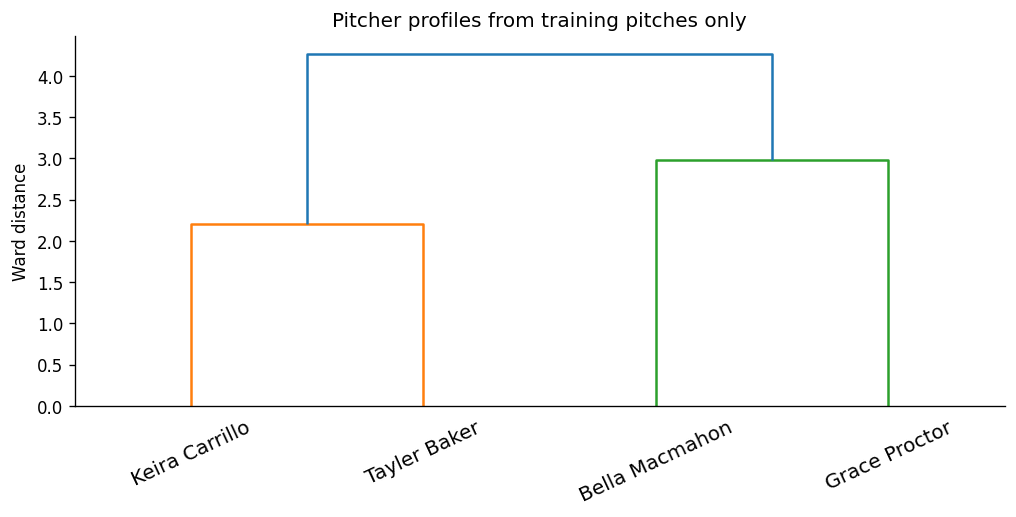

Graph: 08_pitcher_dendrogram.png


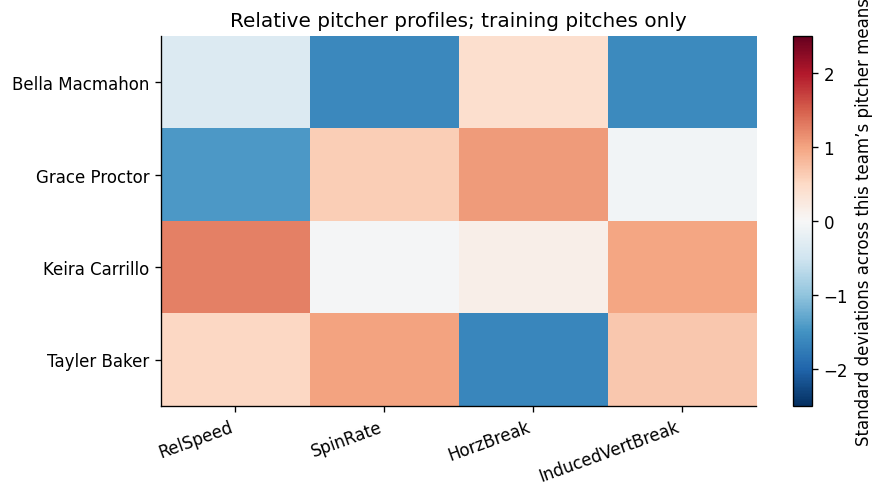

Graph: 09_pitcher_profiles.png
Held-out mean minus training mean, recorded scale:
                RelSpeed  SpinRate  HorzBreak  InducedVertBreak
Pitcher                                                        
Bella Macmahon     2.513     8.390      1.759            -1.105
Grace Proctor      0.019     7.969     -0.841            -0.735
Keira Carrillo    -0.306    70.309     -0.248             0.402
Tayler Baker      -1.877    17.588     -0.423            -0.932


In [19]:
profiles=train.groupby('Pitcher')[FEATURES].mean()
profile_counts=train.groupby('Pitcher').size().rename('training_pitches')
heldout_profiles=test.groupby('Pitcher')[FEATURES].mean().reindex(profiles.index)
profile_scaler=StandardScaler()
Xp=profile_scaler.fit_transform(profiles)
profile_km = KMeans(n_clusters=2,n_init=30,random_state=SEED).fit(Xp) if len(profiles)>2 else None
profile_results=profiles.join(profile_counts)
if profile_km is not None:
    profile_results['illustrative_style_group']=profile_km.labels_
profile_results['throwing_hand']=train.groupby('Pitcher').PitcherThrows.first()
show_table(profile_results.round(3))
profile_results.to_csv(RESULTS/'training_pitcher_profiles.csv')
heldout_profiles.to_csv(RESULTS/'heldout_pitcher_profiles.csv')
if profile_km is not None:
    print('Illustrative pitcher-profile silhouette:',round(sil(Xp,profile_km.labels_),4))
else:
    print('Two pitcher profiles: descriptive comparison only; no pitcher-style clusters or silhouette are fitted.')
plt.figure(figsize=(10,4));dendrogram(linkage(Xp,method='ward'),labels=profiles.index.tolist(),leaf_rotation=25)
plt.ylabel('Ward distance');plt.title('Pitcher profiles from training pitches only')
figure('08_pitcher_dendrogram')
fig,ax=plt.subplots(figsize=(8,4))
im=ax.imshow(Xp,cmap='RdBu_r',vmin=-2.5,vmax=2.5,aspect='auto')
ax.set_xticks(range(4),FEATURES,rotation=20,ha='right');ax.set_yticks(range(len(profiles)),profiles.index)
fig.colorbar(im,ax=ax,label='Standard deviations across this team’s pitcher means')
ax.set_title('Relative pitcher profiles; training pitches only');figure('09_pitcher_profiles')
profile_differences=(heldout_profiles-profiles)
print('Held-out mean minus training mean, recorded scale:')
show_table(profile_differences.round(3))
profile_differences.to_csv(RESULTS/'heldout_minus_train_pitcher_means.csv')

## 9. Check preprocessing sensitivity
Repeat training comparisons using robust scaling, absolute horizontal movement, omitting spin, and median imputation. Keep k fixed and compare assignments on the same complete training pitches. Missing all four features is not imputed into an artificial average pitch. Absolute horizontal movement tests sensitivity to direction and handedness, at the cost of discarding direction. Silhouettes from different feature spaces should not be used to rank the alternatives directly.

In [20]:
sensitivity=[]
for name,cols,transform in [
    ('Robust scaling',FEATURES,RobustScaler()),
    ('Absolute horizontal movement',FEATURES,StandardScaler()),
    ('Velocity plus movement',['RelSpeed','HorzBreak','InducedVertBreak'],StandardScaler())]:
    frame=train[cols].copy()
    if name=='Absolute horizontal movement': frame['HorzBreak']=frame.HorzBreak.abs()
    xx=transform.fit_transform(frame)
    alternative=KMeans(n_clusters=best_k,n_init=30,random_state=SEED).fit(xx)
    sensitivity.append({'choice':name,'train_rows':len(frame),'silhouette_in_own_space':sil(xx,alternative.labels_),
                        'ARI_vs_baseline':float(adjusted_rand_score(train_labels,alternative.labels_))})
impute_rows=train_raw.dropna(subset=FEATURES,how='all')
imputer=SimpleImputer(strategy='median')
imputed=imputer.fit_transform(impute_rows[FEATURES])
impute_scaler=StandardScaler().fit(imputed)
impute_x=impute_scaler.transform(imputed)
impute_model=KMeans(n_clusters=best_k,n_init=30,random_state=SEED).fit(impute_x)
common_x=impute_scaler.transform(imputer.transform(train[FEATURES]))
sensitivity.append({'choice':'Training median imputation','train_rows':len(impute_rows),
                    'silhouette_in_own_space':sil(impute_x,impute_model.labels_),
                    'ARI_vs_baseline':float(adjusted_rand_score(train_labels,impute_model.predict(common_x)))})
sensitivity=pd.DataFrame(sensitivity)
show_table(sensitivity.round(4));sensitivity.to_csv(RESULTS/'training_sensitivity.csv',index=False)

                         choice  train_rows  silhouette_in_own_space  ARI_vs_baseline
0                Robust scaling         100                   0.4017           0.7757
1  Absolute horizontal movement         100                   0.3822           0.7990
2        Velocity plus movement         100                   0.4364           0.8041
3    Training median imputation         100                   0.4437           1.0000


## 10. Summarize this team
The output records all metrics and package versions. Check which pitchers contribute to each group before naming a style. All conclusions are limited to this game, and no cluster indicates superior performance. The original CSV stays unchanged.

In [21]:
summary = f"""Question 5: Can we identify different pitching styles based on velocity, spin rate, and ball movement?

The file has {len(raw)} pitches, {raw.shape[1]} columns and {data.Pitcher.nunique()} pitchers.
The 80/20 pitch split produced {len(train_raw)} training and {len(test_raw)} test rows before missing-feature exclusions.
The complete-case analysis used {len(train)} training pitches and {len(test)} test pitches.
Training silhouette selected k={best_k} among k=2..6.
K-means silhouette: training {metrics['train_silhouette']:.3f}; test {metrics['test_silhouette']:.3f}.
Mean squared standardized distance to training centers: train {train_msd:.3f}; test {test_msd:.3f}.
Ward versus K-means training ARI: {method_ari:.3f}.
Bootstrap median ARI: {metrics['bootstrap_ARI_median']:.3f}.
The first two PCA components preserve {metrics['PCA_first_two_variance']:.1%} of training variation.

These results describe pitch groups and exploratory pitcher profiles within one game.
They do not establish stable population-level pitching styles or identify superior pitchers.
Signed movement, pitcher identity, missing tracking, unequal pitch counts and repertoire mix limit interpretation.
"""
print(summary)
(RESULTS/'summary.txt').write_text(summary,encoding='utf-8')
(RESULTS/'metrics.json').write_text(json.dumps(metrics,indent=2),encoding='utf-8')
versions={'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,
          'scipy':scipy.__version__,'scikit-learn':sklearn.__version__,'matplotlib':matplotlib.__version__}
print('Versions:',versions)
(RESULTS/'versions.json').write_text(json.dumps(versions,indent=2),encoding='utf-8')
assert sum(np.bincount(train_labels))==len(train)
assert sum(np.bincount(test_labels,minlength=best_k))==len(test)
assert len(assigned)==len(train)+len(test)
assert np.allclose(scaler.mean_,train[FEATURES].mean().values)
assert assigned.source_row.is_unique
print('Verification passed: partitions disjoint, counts reconcile, finite features, training-only scale parameters.')

Question 5: Can we identify different pitching styles based on velocity, spin rate, and ball movement?

The file has 131 pitches, 125 columns and 4 pitchers.
The 80/20 pitch split produced 104 training and 27 test rows before missing-feature exclusions.
The complete-case analysis used 100 training pitches and 24 test pitches.
Training silhouette selected k=6 among k=2..6.
K-means silhouette: training 0.444; test 0.365.
Mean squared standardized distance to training centers: train 0.900; test 1.204.
Ward versus K-means training ARI: 0.875.
Bootstrap median ARI: 0.869.
The first two PCA components preserve 66.0% of training variation.

These results describe pitch groups and exploratory pitcher profiles within one game.
They do not establish stable population-level pitching styles or identify superior pitchers.
Signed movement, pitcher identity, missing tracking, unequal pitch counts and repertoire mix limit interpretation.

Versions: {'python': '3.13.16', 'numpy': '2.1.3', 'pandas': '2.

## Observed South Dakota State findings
The team has 131 recorded pitches and 4 pitchers. Before exclusions, the split contains 104 training and 27 test rows. Complete-case clustering uses 100 training and 24 test pitches. Training silhouette selects 6 groups. Training silhouette is 0.444; test silhouette is 0.365. The first two PCA components retain 66.0% of training variation.

Training group composition by pitcher:
Bella Macmahon: cluster 0 = 66.7%, cluster 1 = 0.0%, cluster 2 = 0.0%, cluster 3 = 0.0%, cluster 4 = 0.0%, cluster 5 = 33.3%

Grace Proctor: cluster 0 = 42.9%, cluster 1 = 0.0%, cluster 2 = 0.0%, cluster 3 = 7.1%, cluster 4 = 50.0%, cluster 5 = 0.0%

Keira Carrillo: cluster 0 = 0.0%, cluster 1 = 7.7%, cluster 2 = 76.9%, cluster 3 = 7.7%, cluster 4 = 7.7%, cluster 5 = 0.0%

Tayler Baker: cluster 0 = 0.0%, cluster 1 = 61.5%, cluster 2 = 28.2%, cluster 3 = 0.0%, cluster 4 = 0.0%, cluster 5 = 10.3%

These are within-team patterns, not evidence of team superiority or population-level styles.

## Interpreting South Dakota State’s groups
Six groups have the highest training silhouette among the tested values k=2 through 6. Because six is the upper boundary of that search and two groups contain only four and six training pitches, the result should not be called an established optimal number of styles. Training silhouette is 0.444 and test silhouette is 0.365, indicating less clear separation in the small holdout than in training. Group composition overlaps pitcher identities: Grace Proctor contributes to several groups, and Tayler Baker and Keira Carrillo share some groups. This may reflect pitch repertoire and physical-profile differences. All South Dakota State pitch-type labels are missing, so these clusters cannot be verified against recorded pitch names. Additional data, a broader preplanned search, and stronger stability checks would help assess whether these small groups persist.


## Actual comparison metrics
                    selected_k  raw_train_rows  raw_test_rows  complete_train_rows  complete_test_rows  train_silhouette  test_silhouette  train_mean_squared_distance  test_mean_squared_distance  ward_train_silhouette  train_method_ARI  test_method_ARI  bootstrap_ARI_median  PCA_first_two_variance
UTA                        3.0           102.0           26.0                 88.0                24.0            0.7686           0.7105                       0.3948                      0.5678                 0.7686            1.0000           1.0000                1.0000                  0.9426
South_Dakota_State         6.0           104.0           27.0                100.0                24.0            0.4437           0.3654                       0.9000                      1.2040                 0.4140            0.8752           0.8072                0.8689                  0.6602

## Download both teams
Run after both analyses finish. Save your executed notebook separately through File → Download → Download .ipynb.

In [22]:
import shutil
from google.colab import files
archive=shutil.make_archive(str(BASE/'Softball_Team_Results'),'zip',root_dir=BASE/'team_results')
files.download(archive)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>